## Loading the dataset 
#### First, install the necessary libraries 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

#### Load the dataset

In [3]:
df= pd.read_excel("/Users/tam_pr/research/eda/raw_data/ML-CLi-Rev2.xlsx")


In [4]:
df

,Material,MW,MCN,Mce,Mla,AWCe,AWLa,CP,CS,BG,...,CC,CO,COO,O1,O2,Ce,La,Method,Conc,AA
0,CL0,172.1148,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,30.259079,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,5,41.142363
1,CL0,172.1148,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,30.259079,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,5,41.077538
2,CL0,172.1148,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,30.259079,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,5,41.142363
3,CL0,172.1148,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,30.259079,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,20,58.634350
4,CL0,172.1148,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,30.259079,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,20,58.439875
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,CL10,171.9932,0.011628,0.010466,0.001163,4.544342,0.50352,0.529250,5.687981,3.09,...,35.464826,0.783084,4.853098,23.488787,9.948643,23.528019,1.933542,H2O2,100,84.171000
176,CL10,171.9932,0.011628,0.010466,0.001163,4.544342,0.50352,0.529250,5.687981,3.09,...,35.464826,0.783084,4.853098,23.488787,9.948643,23.528019,1.933542,H2O2,100,84.993000
177,CL10,171.9932,0.011628,0.010466,0.001163,4.544342,0.50352,0.529250,5.687981,3.09,...,35.464826,0.783084,4.853098,23.488787,9.948643,23.528019,1.933542,H2O2,250,84.805100
178,CL10,171.9932,0.011628,0.010466,0.001163,4.544342,0.50352,0.529250,5.687981,3.09,...,35.464826,0.783084,4.853098,23.488787,9.948643,23.528019,1.933542,H2O2,250,84.758100


#### CP variable is present in the data set but not on the dictionary sourced form the appendixes of the paper, and the one missing is aparameter. 

#### Ask if they are the same

In [5]:
df.shape

(180, 22)

In [6]:
df.isnull().sum()

Material    0
MW          0
MCN         0
Mce         0
Mla         0
AWCe        0
AWLa        0
CP          0
CS          0
BG          0
ZP          0
DLS         0
CC          0
CO          0
COO         0
O1          0
O2          0
Ce          0
La          0
Method      0
Conc        0
AA          0
dtype: int64

#### No missing data 

##### After analysing the data, I noticed that theres very similar rows, specifically samples that share the same Material tag, Method tag and Conc value, to prevent data leaks when splitting in Test and Train sets, groups will be formed. 

In [7]:
df.groupby(["Material", "Method", "Conc"]).size()

Material  Method  Conc
CL0       ABTS    5       3
                  20      3
                  50      3
                  100     3
                  250     3
          DPPH    5       3
                  20      3
                  50      3
                  100     3
                  250     3
          H2O2    5       3
                  20      3
                  50      3
                  100     3
                  250     3
CL1       ABTS    5       3
                  20      3
                  50      3
                  100     3
                  250     2
          DPPH    5       3
                  20      3
                  50      3
                  100     3
                  250     2
          H2O2    5       3
                  20      3
                  50      3
                  100     3
                  250     2
CL10      ABTS    5       3
                  20      3
                  50      3
                  100     3
                  250    

In [8]:
filtered_df = df[
    (df["Conc"] == 250 )
]
filtered_df.shape



(36, 22)

In [9]:
filtered_df.groupby(["Material", "Method","AA"]).size().shape[0]

35

#### Noticed that theres more observations with certain parameters but the rest of the variables look normal, so not necessarily an outlier as a result of experimentation 

#### Decided to check for duplicates

In [10]:
df.loc[df.duplicated(keep=False)]

,Material,MW,MCN,Mce,Mla,AWCe,AWLa,CP,CS,BG,...,CC,CO,COO,O1,O2,Ce,La,Method,Conc,AA
0,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.000000,0.528725,8.957388,3.10,...,30.259079,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,5,41.142363
2,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.000000,0.528725,8.957388,3.10,...,30.259079,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,5,41.142363
16,CL1,172.10264,0.011621,0.011505,0.000116,4.995598,0.050320,0.529043,7.850385,3.11,...,26.055879,1.120511,6.178317,29.790475,9.770931,26.912525,0.171362,DPPH,5,54.069066
17,CL1,172.10264,0.011621,0.011505,0.000116,4.995598,0.050320,0.529043,7.850385,3.11,...,26.055879,1.120511,6.178317,29.790475,9.770931,26.912525,0.171362,DPPH,5,54.069066
96,CL5,172.05400,0.011624,0.011043,0.000581,4.795111,0.251671,0.530190,6.697266,3.09,...,28.285875,1.080163,4.989612,27.583903,10.084164,27.028883,0.947400,ABTS,50,38.476900
97,CL5,172.05400,0.011624,0.011043,0.000581,4.795111,0.251671,0.530190,6.697266,3.09,...,28.285875,1.080163,4.989612,27.583903,10.084164,27.028883,0.947400,ABTS,50,38.476900
132,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.000000,0.528725,8.957388,3.10,...,30.259079,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,H2O2,250,40.810500
133,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.000000,0.528725,8.957388,3.10,...,30.259079,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,H2O2,250,40.810500
150,CL5,172.05400,0.011624,0.011043,0.000581,4.795111,0.251671,0.530190,6.697266,3.09,...,28.285875,1.080163,4.989612,27.583903,10.084164,27.028883,0.947400,H2O2,5,66.721500
152,CL5,172.05400,0.011624,0.011043,0.000581,4.795111,0.251671,0.530190,6.697266,3.09,...,28.285875,1.080163,4.989612,27.583903,10.084164,27.028883,0.947400,H2O2,5,66.721500


#### Found five exact duplicates across all the dataset


In [11]:
df=df.drop_duplicates()

In [12]:
df.groupby(["Material", "Method", "Conc"]).size()


Material  Method  Conc
CL0       ABTS    5       3
                  20      3
                  50      3
                  100     3
                  250     3
          DPPH    5       2
                  20      3
                  50      3
                  100     3
                  250     3
          H2O2    5       3
                  20      3
                  50      3
                  100     3
                  250     2
CL1       ABTS    5       3
                  20      3
                  50      3
                  100     3
                  250     2
          DPPH    5       2
                  20      3
                  50      3
                  100     3
                  250     2
          H2O2    5       3
                  20      3
                  50      3
                  100     3
                  250     2
CL10      ABTS    5       3
                  20      3
                  50      3
                  100     3
                  250    

#### After revising the rest of the groups, found that most of the concentrations are in groups of 3, but some are in groups of two (could've been a lab mistake?)

#### The data frame is now 175 rows 

In [13]:
df.shape

(175, 22)

#### Now we can safely group to prevent data leakage when splitting

In [14]:
group_id = df.groupby(["Material", "Method", "Conc"]).ngroup()

In [15]:
len(group_id)

175

In [16]:
df["group_id"] = group_id

In [17]:
df.head(20)

,Material,MW,MCN,Mce,Mla,AWCe,AWLa,CP,CS,BG,...,CO,COO,O1,O2,Ce,La,Method,Conc,AA,group_id
0,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,5,41.142363,5
1,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,5,41.077538,5
3,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,20,58.634350,6
4,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,20,58.439875,6
5,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,20,58.688371,6
6,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,50,60.471063,7
7,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,50,60.395433,7
8,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,50,60.503475,7
9,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,100,60.427846,8
10,CL0,172.11480,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,...,2.047129,5.348187,27.857363,7.745397,26.742845,0.000000,DPPH,100,60.579105,8


In [18]:
df.dtypes

Material        str
MW          float64
MCN         float64
Mce         float64
Mla         float64
AWCe        float64
AWLa        float64
CP          float64
CS          float64
BG          float64
ZP          float64
DLS           int64
CC          float64
CO          float64
COO         float64
O1          float64
O2          float64
Ce          float64
La          float64
Method          str
Conc          int64
AA          float64
group_id      int64
dtype: object

#### We can see that we will need to perform One Hot Encoding to translate the categorical variables "Material" and "Method" into numerical ones

In [19]:
ohe_df = df.copy()

In [20]:
ohe_df= df= pd.get_dummies(ohe_df,drop_first=True, columns=["Material","Method"],dtype=int)

In [21]:
ohe_df.shape

(175, 26)

#### On the paper its mentioned that after performing OHE theres 26 independent variables, since I already dropped the first one, (Because if all the variables are 0, automatically it means that is the one thats "missing"), so having only 24 independent variables makes sense

In [22]:
df.head()

,MW,MCN,Mce,Mla,AWCe,AWLa,CP,CS,BG,ZP,...,Ce,La,Conc,AA,group_id,Material_CL1,Material_CL10,Material_CL5,Method_DPPH,Method_H2O2
0,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,26.742845,0.0,5,41.142363,5,0,0,0,1,0
1,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,26.742845,0.0,5,41.077538,5,0,0,0,1,0
3,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,26.742845,0.0,20,58.634350,6,0,0,0,1,0
4,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,26.742845,0.0,20,58.439875,6,0,0,0,1,0
5,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,26.742845,0.0,20,58.688371,6,0,0,0,1,0


#### After our data has succesfully been through the One Hot Encoding process, duplicate detection and grouping succesfully, we can now start looking at how the variables affect one another. 

In [23]:
corr_df = df.copy()

In [24]:
corr_df.drop(columns=["group_id"], inplace=True)

In [26]:
corr_df.head()

,MW,MCN,Mce,Mla,AWCe,AWLa,CP,CS,BG,ZP,...,O2,Ce,La,Conc,AA,Material_CL1,Material_CL10,Material_CL5,Method_DPPH,Method_H2O2
0,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,7.745397,26.742845,0.0,5,41.142363,0,0,0,1,0
1,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,7.745397,26.742845,0.0,5,41.077538,0,0,0,1,0
3,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,7.745397,26.742845,0.0,20,58.634350,0,0,0,1,0
4,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,7.745397,26.742845,0.0,20,58.439875,0,0,0,1,0
5,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,7.745397,26.742845,0.0,20,58.688371,0,0,0,1,0


In [27]:
corr = corr_df.corr(method="pearson")

<function matplotlib.pyplot.show(close=None, block=None)>

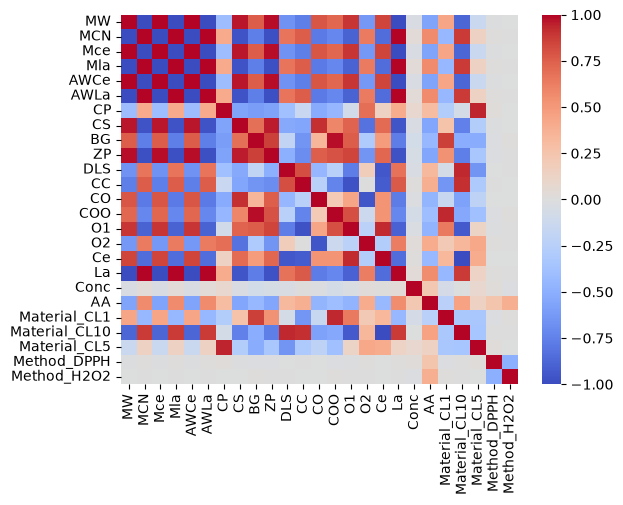

In [28]:
sns.heatmap(corr, cmap="coolwarm", fmt= ".2f")
plt.show

In [30]:
df.to_csv("cleaned_df", index= False)